# 03 What-if: ปรับระดับบิน ±2,000 ฟุต คุ้มไหม

คำถาม business: ถ้าสายการบินยอมเปลี่ยนระดับบินบางเที่ยว จะลดความร้อนจาก contrail (EF) ได้เท่าไหร่ แลกกับน้ำมันที่เพิ่มขึ้นเท่าไหร่ และ ML ช่วยเลือกเที่ยวที่คุ้มได้ดีกว่าการสุ่มแค่ไหน

วิธี (ตาม Teoh et al. 2020):
1. สุ่มเที่ยวบินจากข้อมูลยุโรป แล้วรัน CoCiP ซ้ำ 3 แบบ: ระดับเดิม, สูงขึ้น 2,000 ฟุต, ต่ำลง 2,000 ฟุต
2. เทียบ 3 กลยุทธ์ที่เปลี่ยนเส้นทางจำนวนเที่ยวเท่ากัน
   - **Oracle:** รู้คำตอบจากฟิสิกส์ล่วงหน้า (เพดานสูงสุดที่ทำได้)
   - **ML:** ใช้โมเดลที่ดีที่สุดจาก notebook 02 เลือกเที่ยวและเลือกระดับบิน
   - **Random:** สุ่มเที่ยวและระดับ (เส้นฐาน)
3. วาด MAC curve: ต้นทุนน้ำมันต่อหน่วยความร้อนที่ลดได้ เรียงจากถูกไปแพง

ต้องรัน notebook 01 และ 02 ก่อน (ใช้ ERA5 ที่เก็บไว้ใน Drive ไม่ต้องรอคิวใหม่)

In [1]:
!pip -q install "pycontrails[ecmwf]" xgboost shap interpret imbalanced-learn pyarrow gcsfs zarr h5netcdf h5py

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = pathlib.Path("/content/drive/MyDrive/Environmental-ML-Project")
except ImportError:
    BASE = pathlib.Path("..")
DATA_DIR, FIG_DIR = BASE / "data", BASE / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)
N_FLIGHTS = 200            # จำนวนเที่ยวบินที่ทดลอง (เพิ่มได้ถ้ามีเวลา)
SHIFT_FT = 2000
REROUTE_SHARE = 0.10       # ทุกกลยุทธ์เปลี่ยนเส้นทางได้ 10% ของเที่ยวบินเท่ากัน
FUEL_EUR_PER_KG = 0.75     # สมมติราคาน้ำมันเครื่องบิน ~750 €/ตัน
ETS_EUR_PER_KG_CO2 = 0.07  # สมมติราคาคาร์บอน EU ETS ~70 €/ตัน CO2
CO2_PER_KG_FUEL = 3.16

df = pd.read_parquet(DATA_DIR / "dataset_europe_v1.parquet")
bundle = joblib.load(BASE / "models.joblib")
print(df.shape, "best model:", bundle["best"])

Mounted at /content/drive
(263045, 27) best model: XGBoost


## รัน CoCiP ซ้ำที่ 3 ระดับบิน
ใช้ฟังก์ชันเดียวกับ notebook 01 อ่าน ERA5 (ARCO) ที่ notebook 01 เก็บไว้ใน Drive ถ้าวันไหนยังไม่มีจะโหลดใหม่จาก Google Cloud

In [3]:
import xarray as xr
from pycontrails import Flight, MetDataset
from pycontrails.models.cocip import Cocip
from pycontrails.models.humidity_scaling import ExponentialBoostLatitudeCorrectionHumidityScaling
from pycontrails.models.ps_model import PSFlight

PRESSURE_LEVELS = [400, 350, 300, 250, 225, 200, 175, 150]
REGION, BBOX = "europe", ((-95, 40), (30, 70))   # ต้องตรงกับ notebook 01
ARCO_URL = "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3"
ARCO_PL = {"temperature": "air_temperature", "specific_humidity": "specific_humidity",
           "u_component_of_wind": "eastward_wind", "v_component_of_wind": "northward_wind",
           "vertical_velocity": "lagrangian_tendency_of_air_pressure", "geopotential": "geopotential",
           "specific_cloud_ice_water_content": "specific_cloud_ice_water_content"}
ARCO_RAD = ["top_net_solar_radiation", "top_net_thermal_radiation"]

def _crop(ds):
    (lon0, lon1), (lat0, lat1) = BBOX
    ds = ds.sel(latitude=slice(lat1, lat0))
    ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
    return ds.sel(longitude=slice(lon0, lon1)).sortby("latitude")

def load_met(day):
    cache = DATA_DIR.parent / "era5_arco" / f"{REGION}_{day:%Y%m%d}"
    if not (cache / "pl.nc").exists():
        raise FileNotFoundError(f"ไม่เจอ {cache} ให้รัน notebook 01 วันนี้ก่อน (notebook นี้ใช้ข้อมูลอากาศที่ 01 เก็บไว้)")
    pl = xr.load_dataset(cache / "pl.nc", engine="h5netcdf")
    rad = xr.load_dataset(cache / "rad.nc", engine="h5netcdf")
    for ds in (pl, rad):
        ds.attrs.update(provider="ECMWF", dataset="ERA5", product="reanalysis")
    for v in ARCO_RAD:
        rad[v].attrs["units"] = "J m**-2"
    return MetDataset(pl), MetDataset(rad)

def rebuild(g, shift_ft):
    d = g.sort_values("time")
    data = pd.DataFrame({"longitude": d["longitude"].values, "latitude": d["latitude"].values,
                         "altitude_ft": d["altitude_ft"].values + shift_ft, "time": d["time"].values})
    r = d.iloc[0]
    return Flight(data, attrs={"flight_id": r["flight_id"], "aircraft_type": r["aircraft_type"], "shift_ft": shift_ft})

KEEP = ["air_temperature", "specific_humidity", "rh", "rhi", "u_wind", "v_wind", "air_pressure",
        "fuel_flow", "true_airspeed", "thrust_setting", "engine_efficiency"]

flight_ids = rng.choice(df["flight_id"].unique(), min(N_FLIGHTS, df["flight_id"].nunique()), replace=False)
sample = df[df["flight_id"].isin(flight_ids)].copy()
# ใช้วันที่เครื่องออก ไม่ใช่เวลาของแต่ละจุด เที่ยวบินที่บินข้ามเที่ยงคืนจะได้ไม่ถูกตัดเป็นสองท่อน
sample["day"] = pd.to_datetime(sample.groupby("flight_id")["time"].transform("min")).dt.floor("D")

runs = []
for day, g_day in sample.groupby("day"):
    met, rad = load_met(day)
    cocip = Cocip(met=met, rad=rad, humidity_scaling=ExponentialBoostLatitudeCorrectionHumidityScaling(),
                  aircraft_performance=PSFlight())
    for shift in [0, SHIFT_FT, -SHIFT_FT]:
        flights = [rebuild(g, shift) for _, g in g_day.groupby("flight_id")]
        for fl in cocip.eval(source=flights):
            out = fl.dataframe.copy()
            out = out.loc[:, ~out.columns.duplicated()]
            out["flight_id"], out["aircraft_type"], out["shift_ft"] = fl.attrs["flight_id"], fl.attrs["aircraft_type"], shift
            out["ef"] = out["ef"].fillna(0.0) if "ef" in out else 0.0
            runs.append(out[["flight_id", "aircraft_type", "shift_ft", "time", "longitude", "latitude",
                             "altitude_ft", "ef", "fuel_burn"] + [c for c in KEEP if c in out]])
    print(day.date(), "done")
runs = pd.concat(runs, ignore_index=True)
runs.to_parquet(DATA_DIR / "whatif_runs.parquet")
runs.groupby("shift_ft")[["ef", "fuel_burn"]].sum()

2024-01-08 done
2024-01-09 done
2024-01-10 done
2024-01-11 done
2024-01-12 done
2024-01-13 done
2024-01-14 done


,ef,fuel_burn
shift_ft,,
-2000,3.247267e+16,4.463916e+06
0,4.315102e+16,4.456511e+06
2000,3.948118e+16,4.567475e+06


## ให้ ML ทายตัวร้ายในทุกทางเลือก
ใช้ข้อมูลอากาศที่ระดับบินใหม่ (ไม่ใช่ผล CoCiP) ป้อนให้โมเดล แบบเดียวกับที่สายการบินจะทำได้จริงจากพยากรณ์อากาศ

In [4]:
def add_features(d):
    d = d.sort_values(["flight_id", "shift_ft", "time"]).copy()
    g = d.groupby(["flight_id", "shift_ft"])
    d["rhi_lag5"] = g["rhi"].shift(5).fillna(d["rhi"])
    d["rhi_roll10"] = g["rhi"].transform(lambda s: s.rolling(10, min_periods=1).mean())
    d["temp_lag5"] = g["air_temperature"].shift(5).fillna(d["air_temperature"])
    d["wind_speed"] = np.hypot(d["u_wind"], d["v_wind"])
    t = pd.to_datetime(d["time"])
    lh = (t.dt.hour + t.dt.minute / 60 + d["longitude"] / 15) % 24
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * lh / 24), np.cos(2 * np.pi * lh / 24)
    d["is_night"] = ((lh < 7) | (lh >= 17)).astype(int)
    return d.reset_index(drop=True)

runs = add_features(runs)
X = pd.get_dummies(runs.drop(columns=["ef"]), columns=["aircraft_type"], dtype=float)
X = X.reindex(columns=bundle["features"], fill_value=0)
X = X.fillna(X.median())
feats, model, _, _ = bundle["fitted"][bundle["best"]]
runs["p_villain"] = model.predict_proba(X[feats])[:, 1]

per = runs.groupby(["flight_id", "shift_ft"]).agg(ef=("ef", lambda s: s.clip(lower=0).sum()),
                                                  fuel=("fuel_burn", "sum"),
                                                  ml_score=("p_villain", "sum")).reset_index()
wide = per.pivot(index="flight_id", columns="shift_ft")
wide.head()

ef                              fuel  \
shift_ft                     -2000          0     2000         -2000   
flight_id                                                              
20240108-0007-LISAMS  0.000000e+00  0.000000e+00   0.0   5494.625989   
20240108-0023-PRGDUB  0.000000e+00  0.000000e+00   0.0   3985.840667   
20240108-0030-ARNCDG  0.000000e+00  0.000000e+00   0.0   4277.946448   
20240108-0034-ATHLIS  0.000000e+00  0.000000e+00   0.0  10319.014554   
20240108-0036-CDGYUL  2.217411e+13  5.689974e+11   0.0  34514.617835   

                                                   ml_score            \
shift_ft                      0             2000      -2000      0      
flight_id                                                               
20240108-0007-LISAMS   5506.633592   5641.270533   0.060686  0.040820   
20240108-0023-PRGDUB   4077.177404   4223.173500   0.019584  0.017141   
20240108-0030-ARNCDG   4275.026481   4379.840979   0.028241  0.026865   
20240108-0034-ATHLIS  11299.555983  11634.620583   4.226796  0.055854   
20240108-0036-CDGYUL  34160.268622  34344.286256  12.821715  5.259356   

                                
shift_ft                  2000  
flight_id                       
20240108-0007-LISAMS  0.034279  
20240108-0023-PRGDUB  0.019495  
20240108-0030-ARNCDG  0.029184  
20240108-0034-ATHLIS  0.050418  
20240108-0036-CDGYUL  0.081009

## เทียบ 3 กลยุทธ์ (เปลี่ยนเส้นทางได้ 10% ของเที่ยวบินเท่ากัน)

In [5]:
base_ef, base_fuel = wide["ef"][0], wide["fuel"][0]
alts = [SHIFT_FT, -SHIFT_FT]
n_pick = max(1, int(round(REROUTE_SHARE * len(wide))))

def evaluate(choice):
    # choice: Series flight_id -> shift (0 = ไม่เปลี่ยน)
    ef = sum(wide["ef"][s][f] for f, s in choice.items())
    fuel = sum(wide["fuel"][s][f] for f, s in choice.items())
    return ef, fuel

# Oracle: รู้ EF จริงทุกทางเลือก เลือกเที่ยวที่ลดได้มากที่สุด
best_alt = wide["ef"][alts].idxmin(axis=1)
gain = base_ef - wide["ef"][alts].min(axis=1)
oracle = pd.Series(0, index=wide.index); top = gain.nlargest(n_pick).index
oracle[top] = best_alt[top]

# ML: ใช้คะแนนตัวร้ายของโมเดลทั้งเลือกเที่ยวและเลือกระดับ
ml_best_alt = wide["ml_score"][alts].idxmin(axis=1)
ml_gain = wide["ml_score"][0] - wide["ml_score"][alts].min(axis=1)
ml = pd.Series(0, index=wide.index); top = ml_gain.nlargest(n_pick).index
ml[top] = ml_best_alt[top]

# Random
rand = pd.Series(0, index=wide.index); top = rng.choice(wide.index, n_pick, replace=False)
rand[top] = rng.choice(alts, n_pick)

rows = []
B_ef, B_fuel = base_ef.sum(), base_fuel.sum()
for name, ch in [("Oracle (physics)", oracle), ("ML-targeted", ml), ("Random", rand)]:
    ef, fuel = evaluate(ch)
    d_fuel = fuel - B_fuel
    cost = d_fuel * (FUEL_EUR_PER_KG + CO2_PER_KG_FUEL * ETS_EUR_PER_KG_CO2)
    rows.append({"strategy": name, "flights rerouted": int((ch != 0).sum()),
                 "EF avoided %": 100 * (B_ef - ef) / B_ef if B_ef else np.nan,
                 "fuel change %": 100 * d_fuel / B_fuel,
                 "extra cost €": cost,
                 "€ per TJ avoided": cost / ((B_ef - ef) / 1e12) if B_ef > ef else np.nan})
strategies = pd.DataFrame(rows).round(3)
strategies.to_csv(FIG_DIR / "whatif_strategies.csv", index=False)
strategies

,strategy,flights rerouted,EF avoided %,fuel change %,extra cost €,€ per TJ avoided
0,Oracle (physics),20,43.371,0.882,38154.538,1.976
1,ML-targeted,20,32.604,0.733,31735.117,2.186
2,Random,20,-3.739,0.030,1295.622,NaN


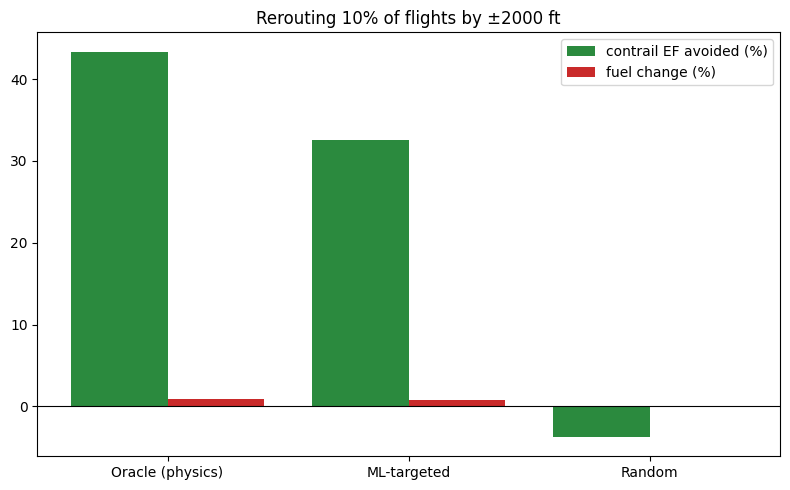

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(strategies))
ax.bar(x - 0.2, strategies["EF avoided %"], 0.4, label="contrail EF avoided (%)", color="#2b8a3e")
ax.bar(x + 0.2, strategies["fuel change %"], 0.4, label="fuel change (%)", color="#c92a2a")
ax.set_xticks(x); ax.set_xticklabels(strategies["strategy"]); ax.axhline(0, c="k", lw=0.8)
ax.set_title(f"Rerouting {int(REROUTE_SHARE * 100)}% of flights by ±{SHIFT_FT} ft"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "whatif_strategies.png", dpi=150); plt.show()

## MAC curve (Marginal Abatement Cost)
แต่ละแท่ง = 1 เที่ยวบินที่เปลี่ยนระดับแล้ว EF ลดลง ความกว้าง = EF ที่ลดได้ ความสูง = ต้นทุนน้ำมันต่อ EF ที่ลด เรียงจากถูกไปแพง แท่งที่ต่ำกว่า 0 คือเที่ยวที่ลด contrail ได้และประหยัดน้ำมันไปด้วย (win-win)

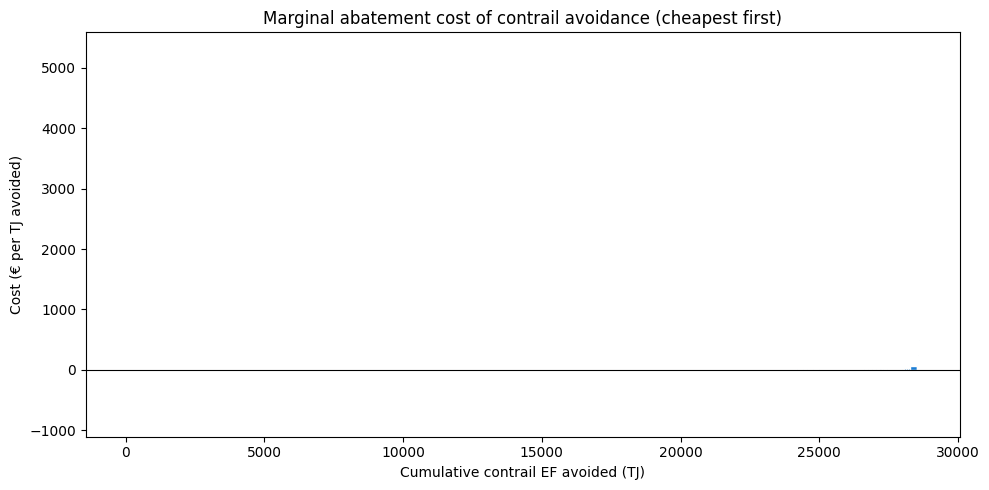

เที่ยวที่ลด EF ได้: 89 จาก 200 เที่ยว, ลดได้รวม 64.3% ของ EF
win-win (ลด EF และประหยัดน้ำมัน): 23 เที่ยว


In [7]:
d_ef = base_ef - wide["ef"][alts].min(axis=1)
d_fuel = pd.Series([wide["fuel"][best_alt[f]][f] for f in wide.index], index=wide.index) - base_fuel
mac = pd.DataFrame({"ef_avoided_TJ": d_ef / 1e12,
                    "cost_eur": d_fuel * (FUEL_EUR_PER_KG + CO2_PER_KG_FUEL * ETS_EUR_PER_KG_CO2)})
mac = mac[mac["ef_avoided_TJ"] > 0]
mac["eur_per_TJ"] = mac["cost_eur"] / mac["ef_avoided_TJ"]
mac = mac.sort_values("eur_per_TJ")
left = np.concatenate([[0], mac["ef_avoided_TJ"].cumsum().values[:-1]])

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(left, mac["eur_per_TJ"], width=mac["ef_avoided_TJ"], align="edge",
       color=np.where(mac["eur_per_TJ"] < 0, "#2b8a3e", "#1c7ed6"), edgecolor="white")
ax.axhline(0, c="k", lw=0.8)
ax.set_xlabel("Cumulative contrail EF avoided (TJ)"); ax.set_ylabel("Cost (€ per TJ avoided)")
ax.set_title("Marginal abatement cost of contrail avoidance (cheapest first)")
plt.tight_layout(); plt.savefig(FIG_DIR / "mac_curve.png", dpi=150); plt.show()

share = mac["ef_avoided_TJ"].sum() * 1e12 / base_ef.sum() if base_ef.sum() else np.nan
print(f"เที่ยวที่ลด EF ได้: {len(mac)} จาก {len(wide)} เที่ยว, ลดได้รวม {share:.1%} ของ EF")
print(f"win-win (ลด EF และประหยัดน้ำมัน): {(mac['eur_per_TJ'] < 0).sum()} เที่ยว")

## ข้อควรระวังในการตีความ
- ราคาน้ำมันและคาร์บอนเป็นค่าสมมติ เปลี่ยนได้ที่ cell ตั้งค่า
- เส้นทางบินเป็นแบบจำลอง ไม่มีช่วงไต่และลด และไม่คิดข้อจำกัดของการจราจรทางอากาศ
- ยังไม่แปลง EF เป็น CO₂ เทียบเท่า เพราะค่าแปลงในงานวิจัยยังไม่แน่นอนสูง จึงเทียบในหน่วยพลังงาน (TJ)